# This Notebook imports the test-CSVs and plots them

We implement different test cases, all defined in mock_publisher.cpp's functions.

## Resting Drone

### No noise ("perfect data")

In [4]:
import pandas as pd

resting_df = pd.read_csv(
    "../tests/resting_ekf/resting_ekf.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df.head())

        t_sec     t_nsec    x    y    z   xq   yq   zq    w
0  1762419802  708537923  0.0  0.0  0.0  0.0  0.0  0.0  1.0
1  1762419802  728533795  0.0  0.0  0.0  0.0  0.0  0.0  1.0
2  1762419802  748355088  0.0  0.0  0.0  0.0  0.0  0.0  1.0
3  1762419802  768710884  0.0  0.0  0.0  0.0  0.0  0.0  1.0
4  1762419802  788532798  0.0  0.0  0.0  0.0  0.0  0.0  1.0


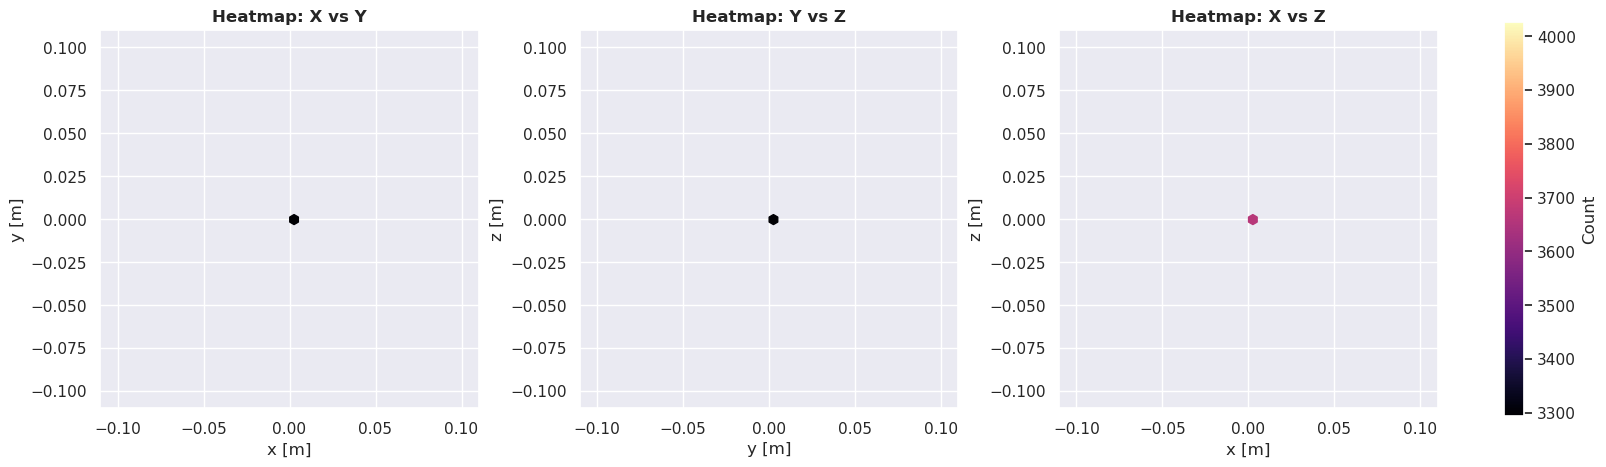

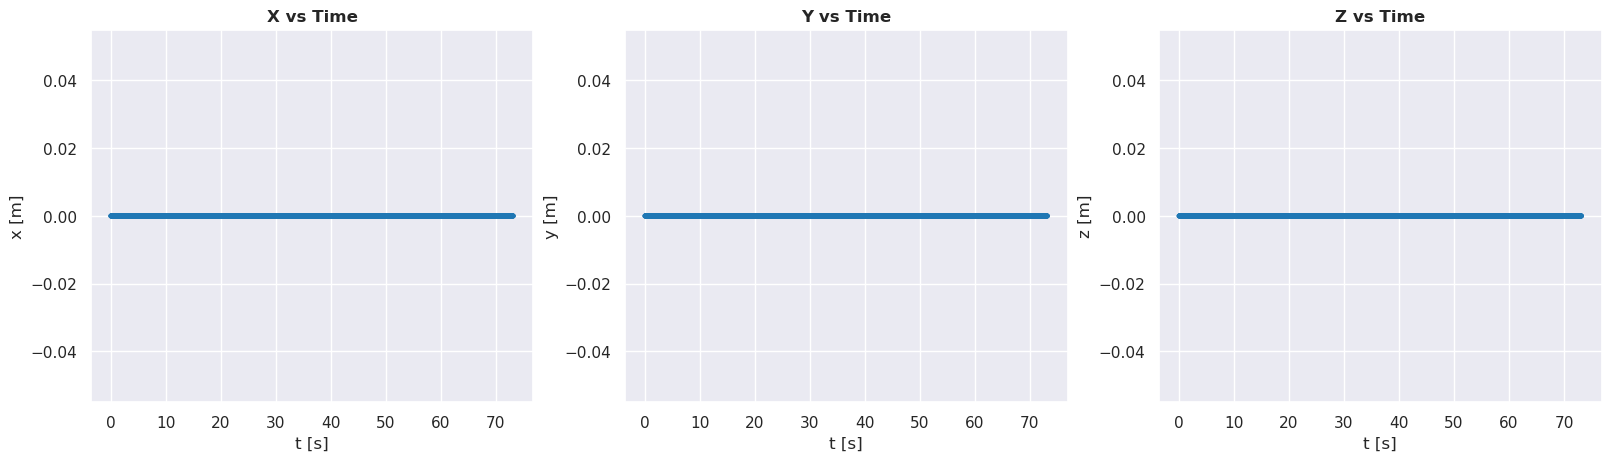

In [6]:
import seaborn as sns

import matplotlib.pyplot as plt

# Style
sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

# Build a continuous time axis in seconds (relative to start for readability)
t = resting_df["t_sec"] + resting_df["t_nsec"] * 1e-9
t_rel = t - t.iloc[0]

# Heatmaps: (x, y), (y, z), (x, z)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
pairs = [("x", "y"), ("y", "z"), ("x", "z")]
mappable = None
for ax, (a, b) in zip(axes, pairs):
    mappable = ax.hexbin(resting_df[a], resting_df[b], gridsize=40, cmap="magma", mincnt=1)
    ax.set_xlabel(f"{a} [m]")
    ax.set_ylabel(f"{b} [m]")
    ax.set_title(f"Heatmap: {a.upper()} vs {b.upper()}", weight="bold")
    ax.set_aspect("equal", "box")
fig.colorbar(mappable, ax=axes, orientation="vertical", label="Count")

# Time series scatter: (t, x), (t, y), (t, z) — plain scatter, no color mapping or colorbar
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, coord in zip(axes2, ["x", "y", "z"]):
    ax.scatter(t_rel, resting_df[coord], s=12, color="tab:blue", alpha=0.85, edgecolors="none")
    ax.set_xlabel("t [s]")
    ax.set_ylabel(f"{coord} [m]")
    ax.set_title(f"{coord.upper()} vs Time", weight="bold")

plt.show()

### Resting Drone with white noise

- Position: $\pm 0.02$
- Orientation: $\pm 0.01$
- Angular velocity: $\pm 0.01$
- Velocity: $\pm 0.01$

$$
\mathbf{Q}=
\begin{bmatrix}
1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2}
\end{bmatrix}
$$


In [10]:
resting_df_white = pd.read_csv(
    "../tests/resting_ekf_white1/resting_ekf_white1.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df_white.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762423878  314417562 -0.001708 -0.000035  0.000872  0.000376  0.000918   
1  1762423878  355122355 -0.000385 -0.000431  0.000843  0.000156  0.000753   
2  1762423878  395758810 -0.000336 -0.000501  0.001174  0.000160  0.000763   
3  1762423878  436590993 -0.000277 -0.000216  0.000946  0.000164  0.000773   
4  1762423878  477336292 -0.000271 -0.000466  0.000684  0.000168  0.000783   

         zq         w  
0 -0.000107  1.000000  
1  0.000577  1.000000  
2  0.000634  0.999999  
3  0.000692  0.999999  
4  0.000750  0.999999  


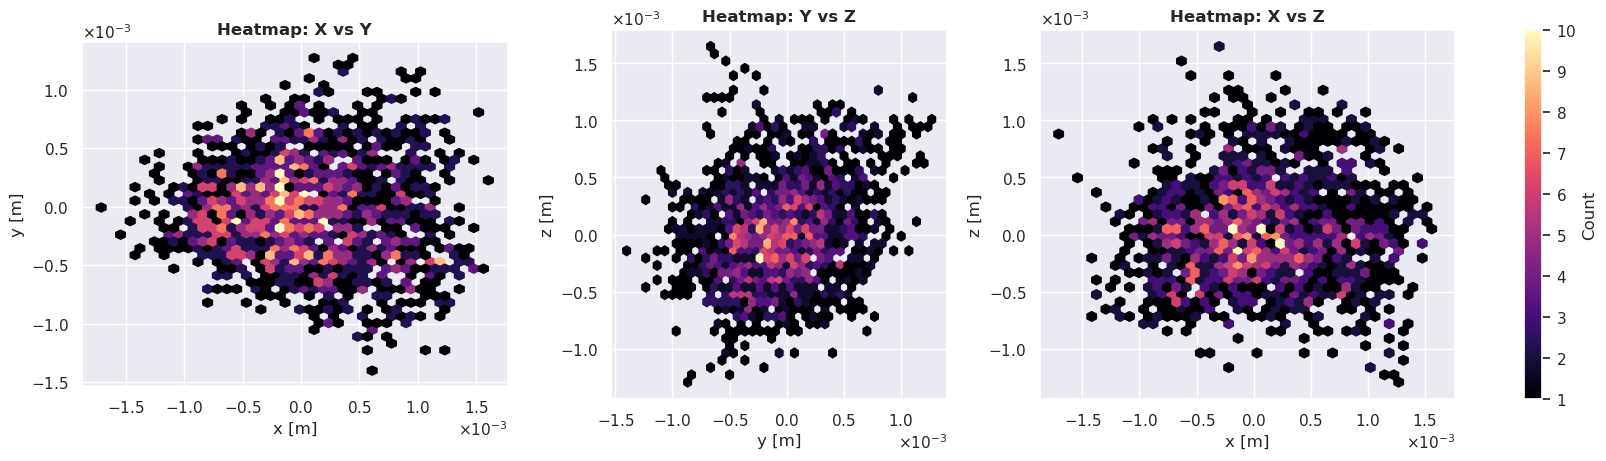

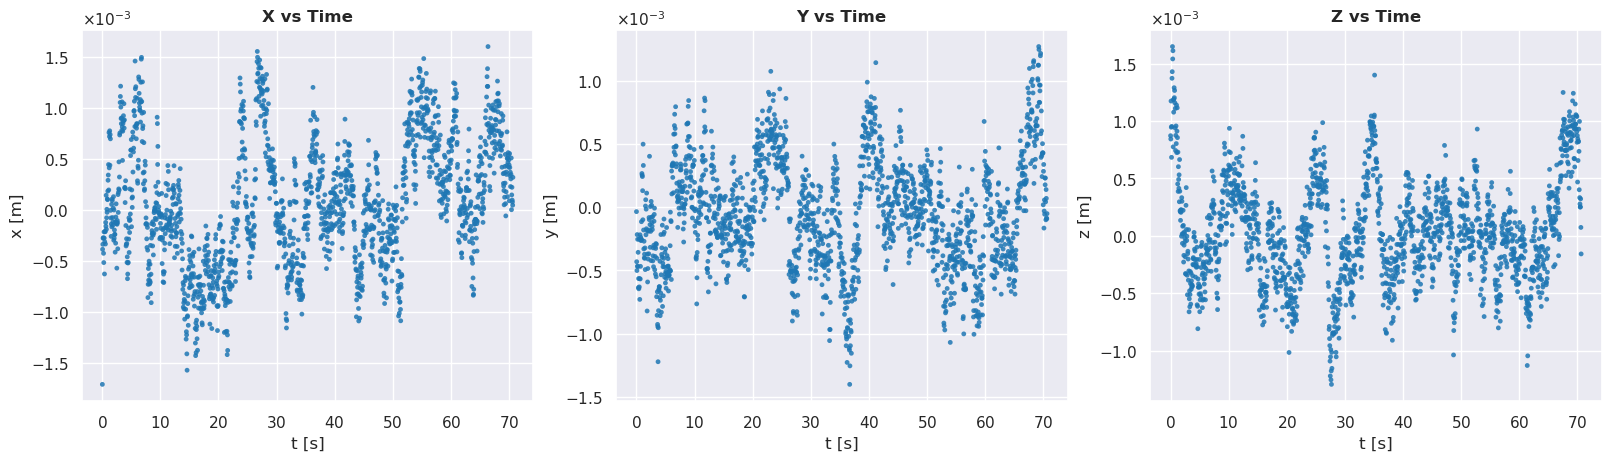

In [ ]:
# Style
sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

# Build a continuous time axis in seconds (relative to start for readability)
t = resting_df_white["t_sec"] + resting_df_white["t_nsec"] * 1e-9
t_rel = t - t.iloc[0]
plt.rcParams["axes.formatter.use_mathtext"] = True
plt.rcParams["axes.formatter.useoffset"] = True
plt.rcParams["axes.formatter.limits"] = (-2, 2)
# Heatmaps: (x, y), (y, z), (x, z)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
pairs = [("x", "y"), ("y", "z"), ("x", "z")]
mappable = None
for ax, (a, b) in zip(axes, pairs):
    mappable = ax.hexbin(resting_df_white[a], resting_df_white[b], gridsize=40, cmap="magma", mincnt=1)
    ax.set_xlabel(f"{a} [m]")
    ax.set_ylabel(f"{b} [m]")
    ax.set_title(f"Heatmap: {a.upper()} vs {b.upper()}", weight="bold")
    ax.set_aspect("equal", "box")
fig.colorbar(mappable, ax=axes, orientation="vertical", label="Count")

# Time series scatter: (t, x), (t, y), (t, z) — plain scatter, no color mapping or colorbar
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, coord in zip(axes2, ["x", "y", "z"]):
    ax.scatter(t_rel, resting_df_white[coord], s=12, color="tab:blue", alpha=0.85, edgecolors="none")
    ax.set_xlabel("t [s]")
    ax.set_ylabel(f"{coord} [m]")
    ax.set_title(f"{coord.upper()} vs Time", weight="bold")

""" 
# Heatmaps: (xq, yq), (yq, zq), (xq, zq)
fig3, axes3 = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
pairs_q = [("xq", "yq"), ("yq", "zq"), ("xq", "zq")]
mappable_q = None
for axq, (aq, bq) in zip(axes3, pairs_q):
    mappable_q = axq.hexbin(resting_df_white[aq], resting_df_white[bq], gridsize=40, cmap="magma", mincnt=1)
    axq.set_xlabel(f"{aq} [-]")
    axq.set_ylabel(f"{bq} [-]")
    axq.set_title(f"Heatmap: {aq.upper()} vs {bq.upper()}", weight="bold")
    axq.set_aspect("equal", "box")
fig3.colorbar(mappable_q, ax=axes3, orientation="vertical", label="Count")

# Time series scatter: (t, xq), (t, yq), (t, zq)
fig4, axes4 = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for axq, coord_q in zip(axes4, ["xq", "yq", "zq"]):
    axq.scatter(t_rel, resting_df_white[coord_q], s=12, color="tab:blue", alpha=0.85, edgecolors="none")
    axq.set_xlabel("t [s]")
    axq.set_ylabel(f"{coord_q} [-]")
    axq.set_title(f"{coord_q.upper()} vs Time", weight="bold") 

"""

plt.show()

### Resting drone with agilicious noise

- Position: $\pm 1.0e-2$
- Orientation: $\pm 1.0e-3$
- Angular velocity: $\pm 1.0e-1$
- Velocity: $\pm 1.0e-2$

$$
\mathbf{Q}=
\begin{bmatrix}
1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3}
\end{bmatrix}
$$


In [16]:
resting_df_white_agi = pd.read_csv(
    "../tests/resting_ekf_white_agi/resting_ekf_white_agi.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df_white_agi.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762426913  592435028 -0.001588 -0.000135  0.005304 -0.004956  0.001887   
1  1762426913  633094499  0.002198 -0.001404  0.004544 -0.005761  0.002202   
2  1762426913  673711699 -0.000769  0.000039 -0.000971  0.003267  0.000355   
3  1762426913  714251275 -0.004424 -0.004263 -0.001351  0.004280  0.000269   
4  1762426913  754835263 -0.002863 -0.001463  0.004265  0.005209  0.000199   

         zq         w  
0  0.000755  0.999986  
1  0.000845  0.999981  
2  0.000140  0.999995  
3  0.000082  0.999991  
4  0.000034  0.999986  


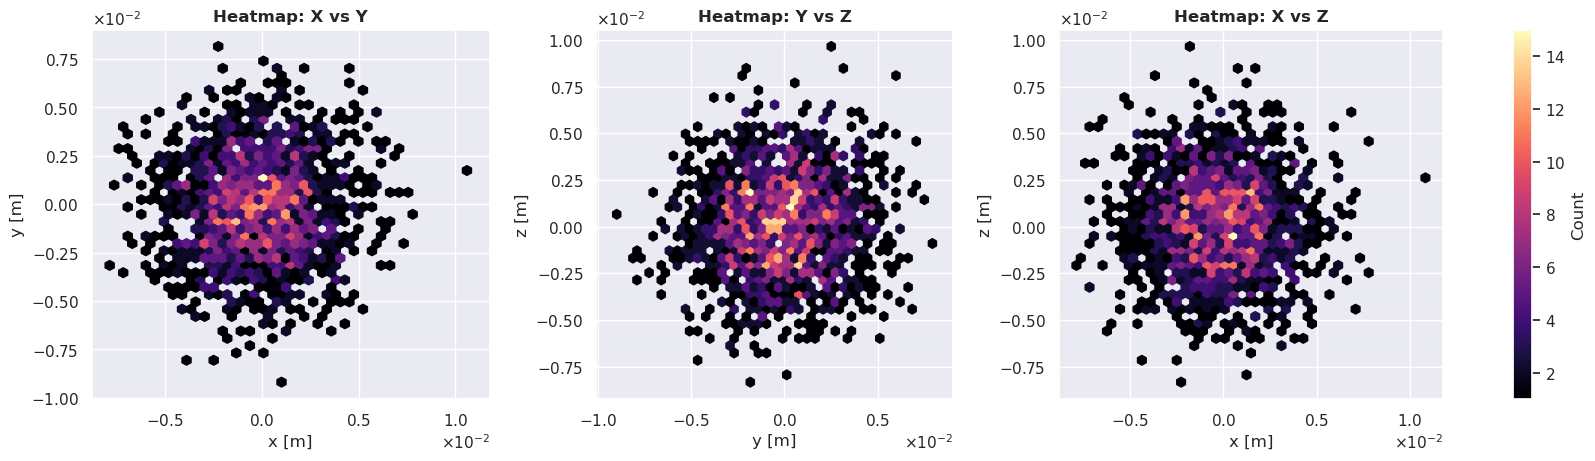

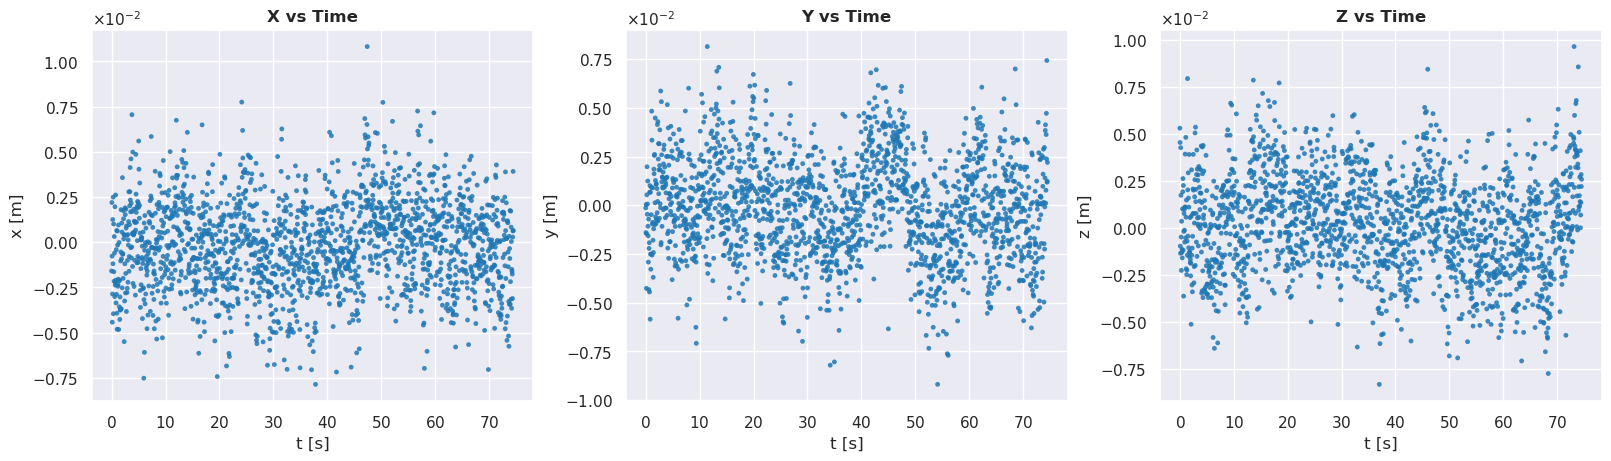

In [18]:
# Style
sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

# Build a continuous time axis in seconds (relative to start for readability)
t = resting_df_white_agi["t_sec"] + resting_df_white_agi["t_nsec"] * 1e-9
t_rel = t - t.iloc[0]
plt.rcParams["axes.formatter.use_mathtext"] = True
plt.rcParams["axes.formatter.useoffset"] = True
plt.rcParams["axes.formatter.limits"] = (-2, 2)
# Heatmaps: (x, y), (y, z), (x, z)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
pairs = [("x", "y"), ("y", "z"), ("x", "z")]
mappable = None
for ax, (a, b) in zip(axes, pairs):
    mappable = ax.hexbin(resting_df_white_agi[a], resting_df_white_agi[b], gridsize=40, cmap="magma", mincnt=1)
    ax.set_xlabel(f"{a} [m]")
    ax.set_ylabel(f"{b} [m]")
    ax.set_title(f"Heatmap: {a.upper()} vs {b.upper()}", weight="bold")
    ax.set_aspect("equal", "box")
fig.colorbar(mappable, ax=axes, orientation="vertical", label="Count")

# Time series scatter: (t, x), (t, y), (t, z) — plain scatter, no color mapping or colorbar
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, coord in zip(axes2, ["x", "y", "z"]):
    ax.scatter(t_rel, resting_df_white_agi[coord], s=12, color="tab:blue", alpha=0.85, edgecolors="none")
    ax.set_xlabel("t [s]")
    ax.set_ylabel(f"{coord} [m]")
    ax.set_title(f"{coord.upper()} vs Time", weight="bold")